# 1) Data Loading and Business Understanding

## Task 1.1 Load dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

RANDOM_STATE = 42

column_names = [
    "status_checking", "duration_months", "credit_history", "purpose", "credit_amount",
    "savings", "employment_since", "installment_rate", "personal_status_sex", "other_debtors",
    "present_residence", "property", "age", "other_installment_plans", "housing",
    "number_credits", "job", "people_liable", "telephone", "foreign_worker", "credit_risk"
]

data_path = Path("../practise3/statlog+german+credit+data/german.data")
if not data_path.exists():
    data_path = Path("practise3/statlog+german+credit+data/german.data")

df = pd.read_csv(data_path, sep=r"\s+", header=None, names=column_names)
df.head()

,status_checking,duration_months,credit_history,purpose,credit_amount,savings,employment_since,installment_rate,personal_status_sex,other_debtors,...,property,age,other_installment_plans,housing,number_credits,job,people_liable,telephone,foreign_worker,credit_risk
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,...,A124,53,A143,A153,2,A173,2,A191,A201,2


## Task 1.2 Understand the target and business problem

This is the same Statlog German Credit dataset used in Practise 3. The original target uses `1` for Good Risk and `2` for Bad Risk. We recode it so class `1` means Bad Risk; this keeps recall focused on detecting risky applications, as in the earlier notebook. In a real lending process, errors can affect both the lender and applicants, so we will examine group-level results as well as overall accuracy.

In [2]:
df["credit_risk"] = df["credit_risk"].map({1: 0, 2: 1})

target_summary = pd.DataFrame({
    "Count": df["credit_risk"].value_counts().reindex([0, 1]),
    "Meaning": ["Good Risk", "Bad Risk"]
})
target_summary

,Count,Meaning
credit_risk,,
0,700,Good Risk
1,300,Bad Risk


Class `1` is Bad Risk. Recall therefore answers: “Of all truly bad-risk applicants in this group, what fraction did the model identify?” It does not mean the model is making a fair loan approval decision by itself.

# 2) Sensitive and Proxy Features

## Task 2.1 Define audit groups

The dataset combines sex and personal status in `personal_status_sex`. We derive a two-group Sex field from the documented category codes. Age is split at 30 as suggested in the assignment. The audit also includes three proxy features: Job, Housing, and Savings account. These can reflect social or economic circumstances indirectly. They are used below to define evaluation groups; the model still receives the original predictor columns, matching the assignment’s group-performance audit setup.

In [ ]:
sex_map = {
    "A91": "Male", "A92": "Female", "A93": "Male",
    "A94": "Male", "A95": "Female"
}
df["Sex"] = df["personal_status_sex"].map(sex_map)
df["Age group"] = np.where(df["age"] < 30, "Under 30", "30 and over")

X = df.drop(columns=["credit_risk", "Sex", "Age group"])
y = df["credit_risk"]
audit_groups = df[["Sex", "Age group", "job", "housing", "savings"]].copy()

job_labels = {
    "A171": "Unemployed / non-resident", "A172": "Unskilled resident",
    "A173": "Skilled employee / official", "A174": "Manager / self-employed / highly qualified"
}
housing_labels = {"A151": "Rent", "A152": "Own", "A153": "Free housing"}
savings_labels = {
    "A61": "Below 100 DM", "A62": "100 to below 500 DM", "A63": "500 to below 1,000 DM",
    "A64": "1,000 DM or more", "A65": "Unknown / no savings account"
}
audit_groups["job"] = audit_groups["job"].map(job_labels)
audit_groups["housing"] = audit_groups["housing"].map(housing_labels)
audit_groups["savings"] = audit_groups["savings"].map(savings_labels)

print("Rows:", len(df))
print("Unmapped Sex values:", int(audit_groups["Sex"].isna().sum()))
print("Target counts (0=Good, 1=Bad):")
print(y.value_counts().sort_index())

audit_groups.head()

Rows: 1000
Unmapped Sex values: 0
Target counts (0=Good, 1=Bad):
credit_risk
0    700
1    300
Name: count, dtype: int64


,Sex,Age group,job,housing,savings
0,Male,30 and over,Skilled employee / official,Own,Unknown / no savings account
1,Female,Under 30,Skilled employee / official,Own,Below 100 DM
2,Male,30 and over,Unskilled resident,Own,Below 100 DM
3,Male,30 and over,Skilled employee / official,Free housing,Below 100 DM
4,Male,30 and over,Skilled employee / official,Free housing,Below 100 DM


All source categories in the supplied dataset should map to Male or Female. We check the unmapped count before modeling so a coding mismatch cannot silently remove a group from the audit.

In [4]:
assert audit_groups["Sex"].notna().all(), "Review the Sex category mapping before continuing."
assert y.notna().all(), "Review the target recoding before continuing."

for feature in audit_groups.columns:
    print(f"\n{feature}")
    display(audit_groups[feature].value_counts(dropna=False).rename("Applicants").to_frame())


Sex


,Applicants
Sex,
Male,690
Female,310



Age group


,Applicants
Age group,
30 and over,629
Under 30,371



job


,Applicants
job,
Skilled employee / official,630
Unskilled resident,200
Manager / self-employed / highly qualified,148
Unemployed / non-resident,22



housing


,Applicants
housing,
Own,713
Rent,179
Free housing,108



savings


,Applicants
savings,
Below 100 DM,603
Unknown / no savings account,183
100 to below 500 DM,103
"500 to below 1,000 DM",63
"1,000 DM or more",48


# 3) Preprocessing

## Task 3.1 Split train/test

We hold out 20% of applicants and stratify by the target so Good/Bad Risk proportions stay similar in both parts. The subgroup analysis uses only this test set. Keeping the test rows out of model fitting gives a more honest estimate of how the fitted model performs on unseen applicants.

In [5]:
X_train, X_test, y_train, y_test, groups_train, groups_test = train_test_split(
    X, y, audit_groups, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Bad-risk share in full data:", round(y.mean(), 3))
print("Bad-risk share in test data:", round(y_test.mean(), 3))

Training rows: 800
Test rows: 200
Bad-risk share in full data: 0.3
Bad-risk share in test data: 0.3


## Task 3.2 Prepare a preprocessing pipeline

Categorical predictors are one-hot encoded and numeric predictors are standardized. The transformations are fitted on the training rows inside a pipeline, which prevents information from the test set leaking into preprocessing. Median and most-frequent imputers make the pipeline robust if a missing value is encountered.

In [6]:
numeric_features = X_train.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]), numeric_features),
        ("categorical", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore"))
        ]), categorical_features)
    ]
)

print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numeric features: 7
Categorical features: 13


# 4) Train a Classification Model

## Task 4.1 Fit Logistic Regression

We use Logistic Regression, one of the baseline models from Practise 3. `class_weight="balanced"` gives the smaller Bad Risk class more influence during fitting. The model and preprocessing are combined so the same fitted pipeline is used for every test group.

In [7]:
model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Model fitted. Test predictions:", len(y_pred))

Model fitted. Test predictions: 200


# 5) Evaluate Overall and Group Performance

## Task 5.1 Overall test metrics

We report accuracy, precision, recall, and F1 for the Bad Risk class. Accuracy alone can hide a group with poor Bad Risk detection, so the same set of metrics will be computed separately for every subgroup. Support shows how many test applicants contributed to each estimate.

In [8]:
overall_metrics = pd.DataFrame([{
    "Group": "All test applicants",
    "Support": len(y_test),
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (Bad Risk)": precision_score(y_test, y_pred, zero_division=0),
    "Recall (Bad Risk)": recall_score(y_test, y_pred, zero_division=0),
    "F1 (Bad Risk)": f1_score(y_test, y_pred, zero_division=0),
    "Bad-risk rate": y_test.mean(),
    "Predicted Bad-risk rate": np.mean(y_pred == 1)
}]).round(3)
overall_metrics

,Group,Support,Accuracy,Precision (Bad Risk),Recall (Bad Risk),F1 (Bad Risk),Bad-risk rate,Predicted Bad-risk rate
0,All test applicants,200,0.75,0.558,0.8,0.658,0.3,0.43


## Task 5.2 Calculate metrics for each feature group

For each audit feature, we subset the held-out test labels and predictions to each category and calculate metrics. “Bad-risk rate” is the share of actual Bad Risk cases in the group. “Predicted Bad-risk rate” is the share labeled Bad Risk by the model. These rates give context for error metrics: groups can have different target prevalence, so raw prediction rates alone do not prove unfair treatment.

In [9]:
def group_metrics(y_true, y_hat, group_values, feature_name):
    rows = []
    audit = pd.DataFrame({"actual": np.asarray(y_true), "predicted": np.asarray(y_hat), "group": np.asarray(group_values)})
    for group_name, part in audit.groupby("group", dropna=False, sort=True):
        rows.append({
            "Feature": feature_name,
            "Group": str(group_name),
            "Support": len(part),
            "Accuracy": accuracy_score(part["actual"], part["predicted"]),
            "Precision (Bad Risk)": precision_score(part["actual"], part["predicted"], zero_division=0),
            "Recall (Bad Risk)": recall_score(part["actual"], part["predicted"], zero_division=0),
            "F1 (Bad Risk)": f1_score(part["actual"], part["predicted"], zero_division=0),
            "Bad-risk rate": part["actual"].mean(),
            "Predicted Bad-risk rate": (part["predicted"] == 1).mean()
        })
    return rows

feature_labels = {
    "Sex": "Sex",
    "Age group": "Age group",
    "job": "Job (proxy)",
    "housing": "Housing (proxy)",
    "savings": "Savings account (proxy)"
}

all_rows = []
for column, label in feature_labels.items():
    all_rows.extend(group_metrics(y_test, y_pred, groups_test[column], label))

group_results = pd.DataFrame(all_rows)
metric_columns = ["Accuracy", "Precision (Bad Risk)", "Recall (Bad Risk)", "F1 (Bad Risk)", "Bad-risk rate", "Predicted Bad-risk rate"]
group_results[metric_columns] = group_results[metric_columns].round(3)
group_results

,Feature,Group,Support,Accuracy,Precision (Bad Risk),Recall (Bad Risk),F1 (Bad Risk),Bad-risk rate,Predicted Bad-risk rate
0,Sex,Female,61,0.738,0.567,0.850,0.680,0.328,0.492
1,Sex,Male,139,0.755,0.554,0.775,0.646,0.288,0.403
2,Age group,30 and over,121,0.785,0.500,0.808,0.618,0.215,0.347
3,Age group,Under 30,79,0.696,0.614,0.794,0.692,0.430,0.557
4,Job (proxy),Manager / self-employed / highly qualified,33,0.606,0.444,0.727,0.552,0.333,0.545
5,Job (proxy),Skilled employee / official,119,0.790,0.627,0.842,0.719,0.319,0.429
6,Job (proxy),Unemployed / non-resident,6,0.500,0.000,0.000,0.000,0.167,0.333
7,Job (proxy),Unskilled resident,42,0.786,0.533,0.800,0.640,0.238,0.357
8,Housing (proxy),Free housing,22,0.727,0.615,0.889,0.727,0.409,0.591
9,Housing (proxy),Own,143,0.755,0.529,0.711,0.607,0.266,0.357


The Support column matters. A metric computed from a small subgroup can change substantially when a few cases differ, so compare sample sizes before interpreting the largest or smallest values.

## Task 5.3 Visualize subgroup metrics

These plots make differences easier to spot. Read the bars together with the support table above; an apparent gap in a small category is less stable than a similar gap backed by many test cases.

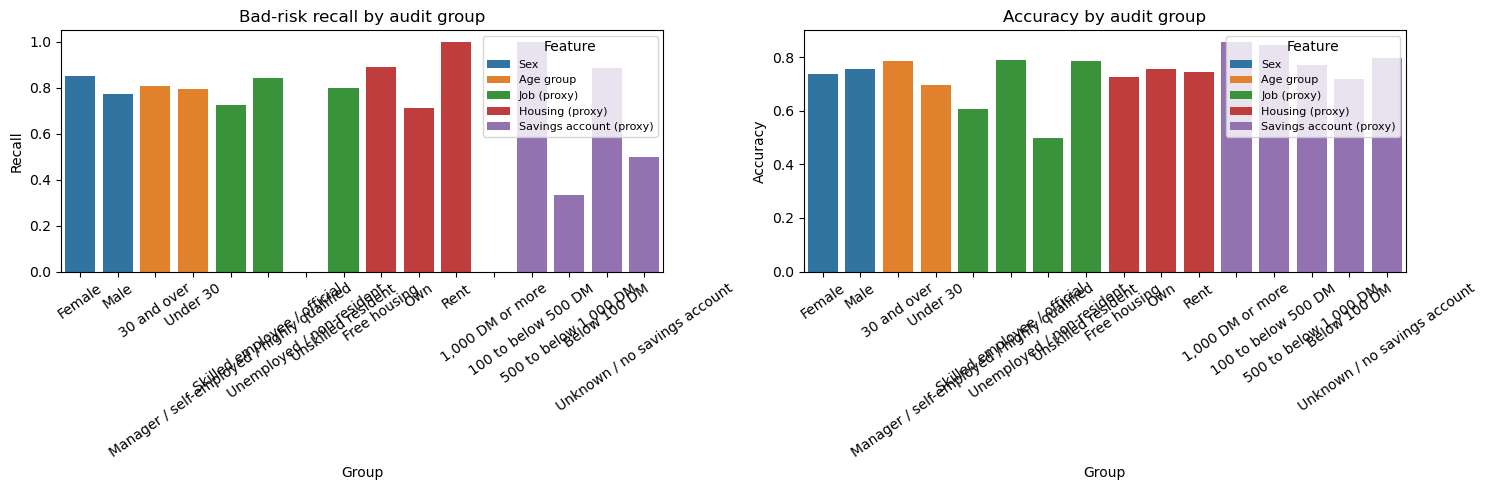

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.barplot(data=group_results, x="Group", y="Recall (Bad Risk)", hue="Feature", ax=axes[0])
axes[0].set_title("Bad-risk recall by audit group")
axes[0].set_xlabel("Group")
axes[0].set_ylabel("Recall")
axes[0].tick_params(axis="x", rotation=35)
axes[0].legend(title="Feature", fontsize=8)

sns.barplot(data=group_results, x="Group", y="Accuracy", hue="Feature", ax=axes[1])
axes[1].set_title("Accuracy by audit group")
axes[1].set_xlabel("Group")
axes[1].set_ylabel("Accuracy")
axes[1].tick_params(axis="x", rotation=35)
axes[1].legend(title="Feature", fontsize=8)
plt.tight_layout()
plt.show()

## Task 5.4 Compare gaps within each feature

We calculate the max-minus-min gap for each metric across categories within each feature. This is a descriptive measure of disparity, not a legal fairness test or proof of discrimination. Always interpret it with group support, uncertainty, the target prevalence, and the model’s intended use.

In [11]:
gap_rows = []
for feature, part in group_results.groupby("Feature", sort=False):
    row = {"Feature": feature, "Smallest group": int(part["Support"].min()), "Largest group": int(part["Support"].max())}
    for metric in ["Accuracy", "Precision (Bad Risk)", "Recall (Bad Risk)", "F1 (Bad Risk)", "Predicted Bad-risk rate"]:
        row[f"{metric} gap"] = part[metric].max() - part[metric].min()
    gap_rows.append(row)
gap_summary = pd.DataFrame(gap_rows).round(3)
gap_summary

,Feature,Smallest group,Largest group,Accuracy gap,Precision (Bad Risk) gap,Recall (Bad Risk) gap,F1 (Bad Risk) gap,Predicted Bad-risk rate gap
0,Sex,61,139,0.017,0.013,0.075,0.034,0.089
1,Age group,79,121,0.089,0.114,0.014,0.074,0.210
2,Job (proxy),6,119,0.290,0.627,0.842,0.719,0.212
3,Housing (proxy),22,143,0.028,0.086,0.289,0.136,0.272
4,Savings account (proxy),7,128,0.138,0.667,1.000,0.800,0.547


The gap table shows the size of each observed range. It does not tell us whether a difference is statistically reliable, and larger gaps can partly reflect different group sizes or different proportions of actual Bad Risk cases.

# 6) Analysis Questions and Business Interpretation

## Task 6.1 Identify the groups with lower results

The next cell prints, for each audit feature, the groups with the lowest accuracy, Bad Risk recall, and F1. Use these results to answer which groups receive worse predictions on the chosen metric. “Worse” depends on the operational cost: low recall means more genuinely bad-risk applicants are missed; low precision means more applicants labeled Bad Risk are actually Good Risk.

In [13]:
for feature, part in group_results.groupby("Feature", sort=False):
    print(f"\n{feature}")
    for metric in ["Accuracy", "Recall (Bad Risk)", "F1 (Bad Risk)"]:
        worst = part.loc[part[metric].idxmin()]
        print(f"Lowest {metric}: {worst['Group']} = {worst[metric]:.3f} (n={int(worst['Support'])})")


Sex
Lowest Accuracy: Female = 0.738 (n=61)
Lowest Recall (Bad Risk): Male = 0.775 (n=139)
Lowest F1 (Bad Risk): Male = 0.646 (n=139)

Age group
Lowest Accuracy: Under 30 = 0.696 (n=79)
Lowest Recall (Bad Risk): Under 30 = 0.794 (n=79)
Lowest F1 (Bad Risk): 30 and over = 0.618 (n=121)

Job (proxy)
Lowest Accuracy: Unemployed / non-resident = 0.500 (n=6)
Lowest Recall (Bad Risk): Unemployed / non-resident = 0.000 (n=6)
Lowest F1 (Bad Risk): Unemployed / non-resident = 0.000 (n=6)

Housing (proxy)
Lowest Accuracy: Free housing = 0.727 (n=22)
Lowest Recall (Bad Risk): Own = 0.711 (n=143)
Lowest F1 (Bad Risk): Own = 0.607 (n=143)

Savings account (proxy)
Lowest Accuracy: Below 100 DM = 0.719 (n=128)
Lowest Recall (Bad Risk): 1,000 DM or more = 0.000 (n=7)
Lowest F1 (Bad Risk): 1,000 DM or more = 0.000 (n=7)


## Task 6.2 Interpretation guide

Use the computed tables above to complete these conclusions in your own words:

- **Does performance differ across groups?** Compare accuracy, Bad Risk recall, precision, and F1 within each feature. Report the metric and the observed gap, and mention support.
- **Which groups consistently receive worse predictions?** Look for groups that are near the bottom on more than one performance metric, not only a low predicted Bad Risk rate.
- **Do proxies reveal additional differences?** Compare the proxy-feature rows (Job, Housing, Savings) with Sex and Age. A proxy can expose disparities that a broad sensitive-feature comparison does not show.
- **Why might differences occur?** The dataset may contain different group sizes, different base rates of Bad Risk, historical patterns, or noisy labels. Model errors can also vary because of these differences and the learned decision boundary.
- **Why does this matter for credit scoring?** A group with lower Bad Risk recall may receive more approvals despite comparable risk; lower precision can lead to more Good Risk applicants being flagged or denied. Either pattern can create financial harm, lost opportunity, and trust or regulatory concerns. A deployed system needs broader validation and human governance.

These are descriptive findings from one train/test split and one model. They do not show that group membership caused an outcome or establish a legal conclusion. For a stronger study, quantify uncertainty, check stability across splits, examine calibration and decision outcomes, and review the applicable law and lending policy.

## Task 6.3 Results for this split

With the fixed 80/20 stratified split and balanced Logistic Regression, overall test accuracy is **0.750**, Bad Risk precision is **0.558**, recall is **0.800**, and F1 is **0.658**.

- **Sex:** accuracy differs by 0.017 and Bad Risk recall by 0.075. Men have lower Bad Risk recall (0.775 vs. 0.850 for women) and lower F1 (0.646 vs. 0.680), while women have slightly lower accuracy (0.738 vs. 0.755). The metrics do not show one sex doing worse on every measure.
- **Age:** applicants under 30 have lower accuracy (0.696 vs. 0.785), but similar Bad Risk recall (0.794 vs. 0.808) and higher F1 (0.692 vs. 0.618). Their actual Bad Risk share is also higher (0.430 vs. 0.215), so the higher predicted Bad Risk rate (0.557 vs. 0.347) should be interpreted with that base-rate difference in mind.
- **Proxy features:** Housing has a notable recall range: applicants with their own housing have 0.711 recall, compared with 1.000 for renters and 0.889 for applicants in free housing. Job and savings show very large metric ranges, but their lowest-recall categories have only 6 applicants (unemployed/non-resident) and 7 applicants (savings of at least 1,000 DM). Those estimates are unstable and should not be treated as firm evidence about the broader groups.

In this split, proxy features surface larger apparent gaps than Sex, especially for Housing, Job, and Savings. The evidence is mixed across metrics, and some proxy categories are very small. These observations motivate a deeper fairness review; they do not establish that the model caused unequal outcomes or that a particular group is treated unfairly in deployment.

# 7) Summary

This notebook trains Logistic Regression on the German Credit data and evaluates it overall and across two explicit sensitive attributes (Sex and Age) plus three proxy features (Job, Housing, Savings account). The group metrics and metric gaps are computed on the same held-out test set. Use the results to describe where performance differs, explain what each error means for applicants and the lender, and state the limits of the analysis.